In [ ]:
# Uncomment kode di bawah ini jika terdapat masalah dengan Java di Windows

import os
import sys

# JAVA = r"C:\path\to\your\java\jdk" # Ganti dengan path JDK yang sesuai

# os.environ["JAVA_HOME"] = JAVA
# os.environ["PATH"] = os.path.join(JAVA, "bin") + os.path.pathsep + os.environ.get("PATH", "")
# os.environ["PYSPARK_PYTHON"] = sys.executable
# os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

## Data Preparation

### Initialization

In [12]:
%pip install -r requirements.txt
import time
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, length, trim, lower, when, concat_ws
from pyspark.ml import Pipeline
from pyspark.ml.classification import LinearSVC
from pyspark.ml.feature import (
    IDF,
    HashingTF,
    Normalizer,
    StringIndexer,
    Tokenizer,
    IndexToString
)
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Uncomment kode di bawah ini jika terdapat masalah dengan direktori sementara Spark di Windows / Resiko OOM (Out of Memory)
# os.makedirs("D:/spark-temp", exist_ok=True)

# Tambahkan konfigurasi spark.local.dir untuk mengatur direktori sementara Spark secara kustom
# .config("spark.local.dir", "D:/spark-temp") \

spark = SparkSession.builder \
    .appName("AmazonReviewsPolarity") \
    .config("spark.driver.memory", "4g") \
    .master("local[*]") \
    .getOrCreate()

sc = spark.sparkContext

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.




[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


### Data Ingestion Method Comparison

In [3]:
t0_start = time.perf_counter()
rdd_test_raw = sc.textFile("datasets/test.csv")
rdd_test_parsed = rdd_test_raw.map(lambda line: line.split("|")).map(
    lambda cols: (
        int(cols[0]) if cols[0].isdigit() else None,
        cols[1] if len(cols) > 1 else "",
        cols[2] if len(cols) > 2 else "",
    )
)

count_rdd = rdd_test_parsed.count()

t0_end = time.perf_counter()
waktu_rdd = t0_end - t0_start
print(
    f"Operasi 1 (RDD API PySpark): {waktu_rdd:.4f} detik | Total"
    f" Baris: {count_rdd}"
)

t1_start = time.perf_counter()

df_test = spark.read.csv(
    "datasets/test.csv", header=False, inferSchema=True
).toDF("label", "title", "text")

count_df = df_test.count()

t1_end = time.perf_counter()
waktu_df = t1_end - t1_start
print(
    f"Operasi 2 (DataFrame PySpark): {waktu_df:.4f} detik | Total"
    f" Baris: {count_df}"
)

selisih = abs(waktu_rdd - waktu_df)
print(f"\nSelisih waktu eksekusi: {selisih:.2f} detik.")

Operasi 1 (RDD API PySpark): 7.6906 detik | Total Baris: 400000
Operasi 2 (DataFrame PySpark): 5.1089 detik | Total Baris: 400000

Selisih waktu eksekusi: 2.58 detik.


### Data Ingestion

In [4]:
df_train = spark.read.csv("datasets/train.csv", header=True, inferSchema=True)
df_train = df_train.toDF("label", "title", "text")
df_train.show(5)

df_test.show(5)

+-----+--------------------+--------------------+
|label|               title|                text|
+-----+--------------------+--------------------+
|    2|The best soundtra...|I'm reading a lot...|
|    2|            Amazing!|"This soundtrack ...|
|    2|Excellent Soundtrack|I truly like this...|
|    2|Remember, Pull Yo...|If you've played ...|
|    2|an absolute maste...|I am quite sure a...|
+-----+--------------------+--------------------+
only showing top 5 rows
+-----+--------------------+--------------------+
|label|               title|                text|
+-----+--------------------+--------------------+
|    2|            Great CD|"My lovely Pat ha...|
|    2|One of the best g...|Despite the fact ...|
|    1|Batteries died wi...|I bought this cha...|
|    2|works fine, but M...|Check out Maha En...|
|    2|Great for the non...|Reviewed quite a ...|
+-----+--------------------+--------------------+
only showing top 5 rows


## Data Exploration & Data Preprocessing

### Data Exploration

In [5]:
# Data Schema

df_train.printSchema()
df_train.describe("label").show()
print(f"Total Rows in Train Data Title Column: {df_train.select('title').count()}")
print(f"Total Rows in Train Data Text Column: {df_train.select('text').count()}")

print("\n")

df_test.printSchema()
df_test.describe("label").show()
print(f"Total Rows in Test Data Title Column : {df_test.select('title').count()}")
print(f"Total Rows in Test Data Text Column: {df_test.select('text').count()}")

# Detect Missing Values

def detect_missing_values(df, dataset_name):
    print(f"{dataset_name} missing values:")
    missing_values = {}
    for column in df.columns:
        total_null = df.filter(col(column).isNull()).count()
        missing_values[column] = total_null
    print(missing_values)

# Detect Duplicates

def detect_duplicates(df, dataset_name):
    print(f"{dataset_name} duplicates:")
    duplicate_count = df.groupBy(df.columns).count().filter(col("count") > 1).count()
    print(duplicate_count)

root
 |-- label: integer (nullable = true)
 |-- title: string (nullable = true)
 |-- text: string (nullable = true)

+-------+------------------+
|summary|             label|
+-------+------------------+
|  count|           3599999|
|   mean|1.4999998611110725|
| stddev|0.5000000694444585|
|    min|                 1|
|    max|                 2|
+-------+------------------+

Total Rows in Train Data Title Column: 3599999
Total Rows in Train Data Text Column: 3599999


root
 |-- label: integer (nullable = true)
 |-- title: string (nullable = true)
 |-- text: string (nullable = true)

+-------+-----------------+
|summary|            label|
+-------+-----------------+
|  count|           400000|
|   mean|              1.5|
| stddev|0.500000625001172|
|    min|                1|
|    max|                2|
+-------+-----------------+

Total Rows in Test Data Title Column : 400000
Total Rows in Test Data Text Column: 400000


### Data Cleaning

In [6]:
def clean_data(df, dataset_name):

    print("Before Data Cleaning:")
    detect_missing_values(df, dataset_name)
    detect_duplicates(df, dataset_name)

    
    df_clean = df.dropna()
    
    df_clean = df_clean.dropDuplicates(["title", "text"])
    
    df_clean = df_clean \
        .withColumn("title", trim(col("title"))) \
        .withColumn("text", trim(col("text")))
    
    invalid_words = ["n/a", "null", "undefined", "-"]
    
    df_clean = df_clean.filter(
        col("label").isin(1, 2) &
        (length(col("title")) >= 3) &
        (length(col("text")) >= 3) &
        (~lower(col("text")).isin(invalid_words))
    )

    print("After Data Cleaning:")
    detect_missing_values(df, dataset_name)
    detect_duplicates(df, dataset_name)
    
    return df_clean

In [7]:
df_train = clean_data(df_train, "Train Dataset")
df_test = clean_data(df_test, "Test Dataset")

Before Data Cleaning:
Train Dataset missing values:
{'label': 0, 'title': 48, 'text': 13}
Train Dataset duplicates:
297
After Data Cleaning:
Train Dataset missing values:
{'label': 0, 'title': 48, 'text': 13}
Train Dataset duplicates:
297
Before Data Cleaning:
Test Dataset missing values:
{'label': 0, 'title': 4, 'text': 1}
Test Dataset duplicates:
4
After Data Cleaning:
Test Dataset missing values:
{'label': 0, 'title': 4, 'text': 1}
Test Dataset duplicates:
4


### Feature Engineering

In [ ]:
df_train_feat = df_train.withColumn("text_length", length(col("text")))\
    .withColumn(
        "length_category",
        when(col("text_length") < 100, "Short")
        .when(col("text_length").between(100, 300), "Medium")
        .otherwise("Long")
    )\
    .withColumn(
        "sentiment",
        when(col("label") == 1, "Negative").otherwise("Positive")
    )\
    .withColumn("full_text", concat_ws(" ", col("title"), col("text")))

df_test_feat = df_test.withColumn("text_length", length(col("text")))\
    .withColumn(
        "length_category",
        when(col("text_length") < 100, "Short")
        .when(col("text_length").between(100, 300), "Medium")
        .otherwise("Long")
    )\
    .withColumn(
        "sentiment",
        when(col("label") == 1, "Negative").otherwise("Positive")
    )\
    .withColumn("full_text", concat_ws(" ", col("title"), col("text")))

### Data Visualization

C:\Users\ASUS\AppData\Roaming\Python\Python312\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


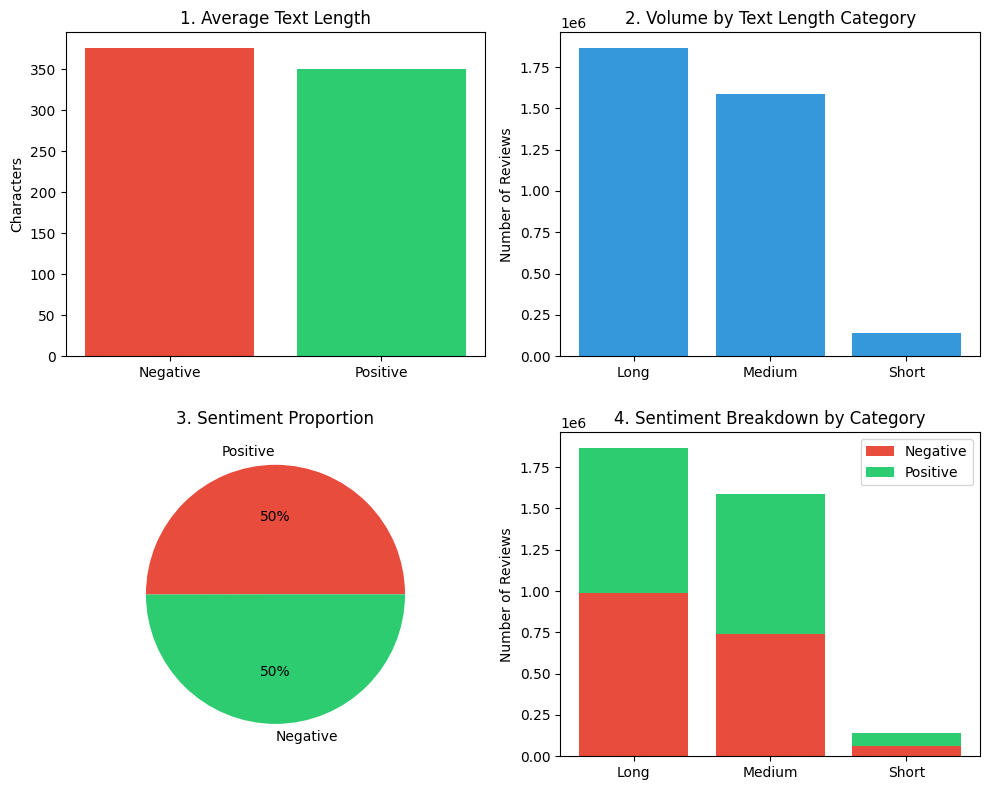

In [9]:
pdf = df_train_feat.select(
    "sentiment", "length_category", "text_length"
).toPandas()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

df_train_avg = pdf.groupby("sentiment")["text_length"].mean()
axes[0, 0].bar(
    df_train_avg.index, df_train_avg.values, color=["#e74c3c", "#2ecc71"]
)
axes[0, 0].set_title("1. Average Text Length")
axes[0, 0].set_ylabel("Characters")

df_train_cat = pdf["length_category"].value_counts()
axes[0, 1].bar(df_train_cat.index, df_train_cat.values, color="#3498db")
axes[0, 1].set_title("2. Volume by Text Length Category")
axes[0, 1].set_ylabel("Number of Reviews")

df_train_sent = pdf["sentiment"].value_counts()
axes[1, 0].pie(
    df_train_sent.values,
    labels=df_train_sent.index,
    autopct="%1.0f%%",
    colors=["#e74c3c", "#2ecc71"],
)
axes[1, 0].set_title("3. Sentiment Proportion")

df_pivot = (
    pdf.groupby(["length_category", "sentiment"]).size().unstack().fillna(0)
)
axes[1, 1].bar(
    df_pivot.index, df_pivot["Negative"], label="Negative", color="#e74c3c"
)
axes[1, 1].bar(
    df_pivot.index,
    df_pivot["Positive"],
    bottom=df_pivot["Negative"],
    label="Positive",
    color="#2ecc71",
)
axes[1, 1].set_title("4. Sentiment Breakdown by Category")
axes[1, 1].set_ylabel("Number of Reviews")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## Machine Learning Model

TF-IDF (Term Frequency - Inverse Document Frequency) + Linear SVM (Support Vector Machine) Binary Sentiment Classification

### Model Pipelines

In [10]:
tokenizer = Tokenizer(inputCol="full_text", outputCol="words")

hashingTF = HashingTF(
    inputCol="words", outputCol="rawFeatures", numFeatures=10000
)

idf = IDF(inputCol="rawFeatures", outputCol="idfFeatures")

normalizer = Normalizer(inputCol="idfFeatures", outputCol="features", p=2.0)

label_indexer = StringIndexer(inputCol="label", outputCol="label_index")

svm = LinearSVC(featuresCol="features", labelCol="label_index", maxIter=15)

label_converter = IndexToString(
    inputCol="prediction",
    outputCol="predicted_label",
    labels=label_indexer.fit(df_train).labels,
)

pipeline = Pipeline(
    stages=[tokenizer, hashingTF, idf, normalizer, label_indexer, svm, label_converter]
)

model = pipeline.fit(df_train_feat)

predictions = model.transform(df_test_feat)

predictions.select("text", "label", "predicted_label").show(100)

+--------------------+-----+---------------+
|                text|label|predicted_label|
+--------------------+-----+---------------+
|I purchased a twi...|    2|              2|
|I used it once an...|    1|              1|
|I have used this ...|    1|              1|
|movies are okay b...|    1|              1|
|I was in 9th grad...|    2|              2|
|"Clay's voice soa...|    2|              2|
|This movie is ver...|    2|              2|
|I bought this fro...|    2|              1|
|This movie isnt e...|    1|              1|
|"This review rela...|    2|              2|
|"The character wa...|    1|              1|
|I must admit that...|    1|              1|
|be careful, when ...|    1|              1|
|According to this...|    1|              1|
|I found this vers...|    1|              1|
|"I had seen this ...|    2|              1|
|Overall a very go...|    2|              2|
|Another business ...|    1|              1|
|I have not heard ...|    2|              1|
|I am not 

### Model Evaluation

In [11]:
evaluator = MulticlassClassificationEvaluator(
    labelCol="label_index",
    predictionCol="prediction",
)

accuracy = evaluator.setMetricName("accuracy").evaluate(predictions)
f1 = evaluator.setMetricName("f1").evaluate(predictions)
precision = evaluator.setMetricName("weightedPrecision").evaluate(predictions)
recall = evaluator.setMetricName("weightedRecall").evaluate(predictions)

print(f"Accuracy  : {accuracy:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")

Accuracy  : 0.8684
F1-Score  : 0.8684
Precision : 0.8684
Recall    : 0.8684
